In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error
from matplotlib import pyplot as plt

# Configuração para exibir todas as colunas que vamos criar
pd.set_option('display.max_columns', None)

print("Ambiente configurado com sucesso! 🚀")

Ambiente configurado com sucesso! 🚀


In [2]:
#Importando os dados trabalhados do EDA
df = pd.read_csv('dados.csv', delimiter=',', header='infer')
df['data'] = pd.to_datetime(df['data'])
df = df[df['data'] >= '2000-01-01'].copy()
df = df.sort_values('data').reset_index(drop=True)

print(f"Formato do dataframe: {df.shape[0]} meses registrados.")
df.head()

Formato do dataframe: 316 meses registrados.


,data,ipca,selic,cambio,igpm
0,2000-01-01,0.62,18.94,1.8037,1.24
1,2000-02-01,0.13,18.87,1.7753,0.35
2,2000-03-01,0.22,18.85,1.7420,0.15
3,2000-04-01,0.42,18.62,1.7682,0.23
4,2000-05-01,0.01,18.51,1.8279,0.31


XGBoost, ele não entende o conceito de tempo nativamente.

* primeiro passo é extrair informações numéricas da própria data.
    * mes
    * ano

In [3]:
#criando features de calendário
df['ano'] = df['data'].dt.year
df['mes'] = df['data'].dt.month

df.head()

,data,ipca,selic,cambio,igpm,ano,mes
0,2000-01-01,0.62,18.94,1.8037,1.24,2000,1
1,2000-02-01,0.13,18.87,1.7753,0.35,2000,2
2,2000-03-01,0.22,18.85,1.7420,0.15,2000,3
3,2000-04-01,0.42,18.62,1.7682,0.23,2000,4
4,2000-05-01,0.01,18.51,1.8279,0.31,2000,5


criação de lags ou Defasagens
 * se quisermos que ele preveja o IPCA do mês que vem, precisamos dar a ele pistas do passado recente na mesma linha

 * lag1 -> ipca do mês anterior 
 * lag2 -> ipca de dois meses atrás (base para justificativa do lag1, pois ele captura a tendência de curto prazo)
 * lag12 -> ipca de 1 ano atrás (captura a sazonalidade anual de forma direta).

In [4]:
#Lags para o IPCA 
df['ipca_lag1'] = df['ipca'].shift(1)
df['ipca_lag2'] = df['ipca'].shift(2)
df['ipca_lag12'] = df['ipca'].shift(12)

# Criando os Lags para as variáveis exógenas (Selic, Câmbio e igpm)
df['selic_lag_1'] = df['selic'].shift(1)
df['selic_lag_2'] = df['selic'].shift(2)
df['selic_lag_3'] = df['selic'].shift(3)

df['cambio_lag_1'] = df['cambio'].shift(1)
df['cambio_lag_2'] = df['cambio'].shift(2)
df['cambio_lag_3'] = df['cambio'].shift(3)

df['igpm_lag_1'] = df['igpm'].shift(1)
df['igpm_lag_2'] = df['igpm'].shift(2)
df['igpm_lag_3'] = df['igpm'].shift(3)

df.head(5)

,data,ipca,selic,cambio,igpm,ano,mes,ipca_lag1,ipca_lag2,ipca_lag12,selic_lag_1,selic_lag_2,selic_lag_3,cambio_lag_1,cambio_lag_2,cambio_lag_3,igpm_lag_1,igpm_lag_2,igpm_lag_3
0,2000-01-01,0.62,18.94,1.8037,1.24,2000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-02-01,0.13,18.87,1.7753,0.35,2000,2,0.62,NaN,NaN,18.94,NaN,NaN,1.8037,NaN,NaN,1.24,NaN,NaN
2,2000-03-01,0.22,18.85,1.7420,0.15,2000,3,0.13,0.62,NaN,18.87,18.94,NaN,1.7753,1.8037,NaN,0.35,1.24,NaN
3,2000-04-01,0.42,18.62,1.7682,0.23,2000,4,0.22,0.13,NaN,18.85,18.87,18.94,1.7420,1.7753,1.8037,0.15,0.35,1.24
4,2000-05-01,0.01,18.51,1.8279,0.31,2000,5,0.42,0.22,NaN,18.62,18.85,18.87,1.7682,1.7420,1.7753,0.23,0.15,0.35


In [5]:
# 1. Removendo as linhas com valores nulos (NaN)
df_limpo = df.dropna().copy()

# 2. Resetando o índice para a contagem começar do 0 (Janeiro de 2001)
df_limpo = df_limpo.reset_index(drop=True)

# 3. Conferindo o resultado
print(f"Linhas originais: {len(df)}")
print(f"Linhas após limpeza: {len(df_limpo)}")
print(f"Primeiro mês da tabela agora: {df_limpo['data'].min()}")

df_limpo.head()

Linhas originais: 316
Linhas após limpeza: 304
Primeiro mês da tabela agora: 2001-01-01 00:00:00


,data,ipca,selic,cambio,igpm,ano,mes,ipca_lag1,ipca_lag2,ipca_lag12,selic_lag_1,selic_lag_2,selic_lag_3,cambio_lag_1,cambio_lag_2,cambio_lag_3,igpm_lag_1,igpm_lag_2,igpm_lag_3
0,2001-01-01,0.57,15.49,1.9545,0.62,2001,1,0.59,0.32,0.62,16.19,16.51,16.60,1.9633,1.9480,1.8796,0.63,0.29,0.38
1,2001-02-01,0.46,15.20,2.0019,0.23,2001,2,0.57,0.59,0.13,15.49,16.19,16.51,1.9545,1.9633,1.9480,0.62,0.63,0.29
2,2001-03-01,0.38,15.39,2.0890,0.56,2001,3,0.46,0.57,0.22,15.20,15.49,16.19,2.0019,1.9545,1.9633,0.23,0.62,0.63
3,2001-04-01,0.58,16.02,2.1925,1.00,2001,4,0.38,0.46,0.42,15.39,15.20,15.49,2.0890,2.0019,1.9545,0.56,0.23,0.62
4,2001-05-01,0.41,16.43,2.2972,0.86,2001,5,0.58,0.38,0.01,16.02,15.39,15.20,2.1925,2.0890,2.0019,1.00,0.56,0.23


recorte de treino e teste

In [6]:
# Definindo o corte: Treino até Dez/2025, Teste em 2026
data_corte = '2026-01-01'

treino = df_limpo[df_limpo['data'] < data_corte].copy()
teste = df_limpo[df_limpo['data'] >= data_corte].copy()

print(f"Treino vai até: {treino['data'].max().strftime('%m/%Y')}")
print(f"Teste começa em: {teste['data'].min().strftime('%m/%Y')}")
print(f"Meses no teste: {len(teste)}")

Treino vai até: 12/2025
Teste começa em: 01/2026
Meses no teste: 4


feature selection

In [7]:
# Selecionamos apenas as colunas de lags e as informações de calendário
features = [col for col in df_limpo.columns if 'lag' in col or col in ['mes', 'ano']]

X_train = treino[features]
y_train = treino['ipca']

X_test = teste[features]
y_test = teste['ipca']

print(f"O modelo usará as seguintes pistas: {features}")

O modelo usará as seguintes pistas: ['ano', 'mes', 'ipca_lag1', 'ipca_lag2', 'ipca_lag12', 'selic_lag_1', 'selic_lag_2', 'selic_lag_3', 'cambio_lag_1', 'cambio_lag_2', 'cambio_lag_3', 'igpm_lag_1', 'igpm_lag_2', 'igpm_lag_3']


Definição do modelo XGboost

In [24]:
#Definindo o modelo
modelo_xgb = xgb.XGBRegressor(n_estimators=1000,
                              learning_rate = 0.01,
                              max_depth=5,
                              early_stopping_rounds=100,  #Se o validation_1 parar de cair e não melhorar por 50 rodadas seguidas, pare tudo
                              random_state=42
                              )

# 2. Treinando o modelo 
# O verbose=100 serve para ele te dar um "sinal de vida" a cada 100 árvores criadas
modelo_xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    
    verbose=100
)

[0]	validation_0-rmse:0.38761	validation_1-rmse:0.24847
[100]	validation_0-rmse:0.24654	validation_1-rmse:0.24855
[200]	validation_0-rmse:0.18391	validation_1-rmse:0.23258
[300]	validation_0-rmse:0.14806	validation_1-rmse:0.21972
[400]	validation_0-rmse:0.12457	validation_1-rmse:0.21688
[423]	validation_0-rmse:0.11987	validation_1-rmse:0.21772


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,100
,enable_categorical,False
,eval_metric,None


In [25]:
# Fazendo a previsão apenas com os meses de teste (2026)
previsoes_2026 = modelo_xgb.predict(X_test)

# Criando um DataFrame para comparar
df_comparativo = pd.DataFrame({
    'Data': teste['data'],
    'IPCA_Real': y_test.values,
    'IPCA_XGBoost': previsoes_2026
})

# Calculando a diferença (Erro)
df_comparativo['Diferenca'] = df_comparativo['IPCA_Real'] - df_comparativo['IPCA_XGBoost']

print("--- Comparativo: Realidade vs XGBoost (2026) ---")
print(df_comparativo)

# Calculando o MAE final
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
mae_final = mean_absolute_error(y_test, previsoes_2026)
rmse_final = root_mean_squared_error(y_test, previsoes_2026)
print(f"\nErro Médio Absoluto (MAE): {mae_final:.4f}")
print(f"\nRaiz do erro ao quadrado: {rmse_final:.4f}")

--- Comparativo: Realidade vs XGBoost (2026) ---
          Data  IPCA_Real  IPCA_XGBoost  Diferenca
300 2026-01-01       0.33      0.479291  -0.149291
301 2026-02-01       0.70      0.454827   0.245173
302 2026-03-01       0.88      0.563187   0.316813
303 2026-04-01       0.67      0.605431   0.064569

Erro Médio Absoluto (MAE): 0.1940

Raiz do erro ao quadrado: 0.2162


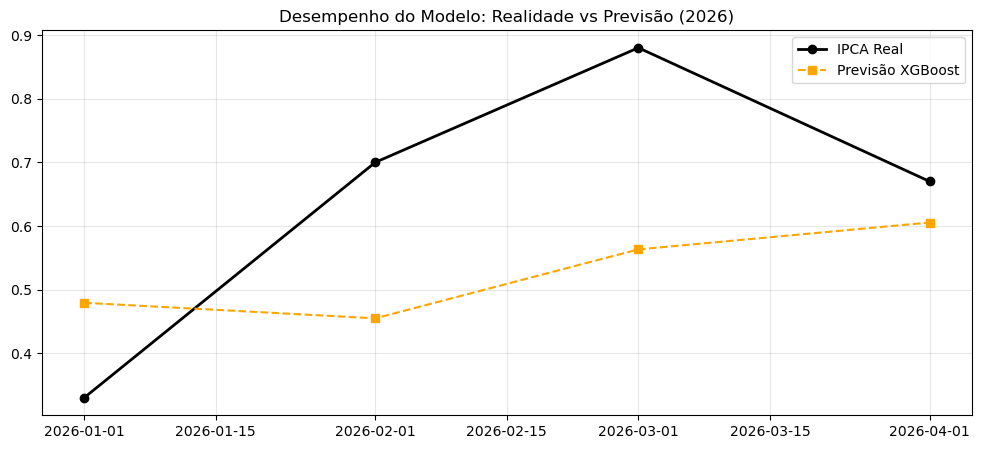

In [26]:
plt.figure(figsize=(12, 5))
plt.plot(df_comparativo['Data'], df_comparativo['IPCA_Real'], marker='o', label='IPCA Real', color='black', linewidth=2)
plt.plot(df_comparativo['Data'], df_comparativo['IPCA_XGBoost'], marker='s', label='Previsão XGBoost', color='orange', linestyle='--')

# Se você tiver os dados do Prophet, adicione aqui:
# plt.plot(df_comparativo['Data'], previsoes_prophet, label='Previsão Prophet', color='blue')

plt.title('Desempenho do Modelo: Realidade vs Previsão (2026)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

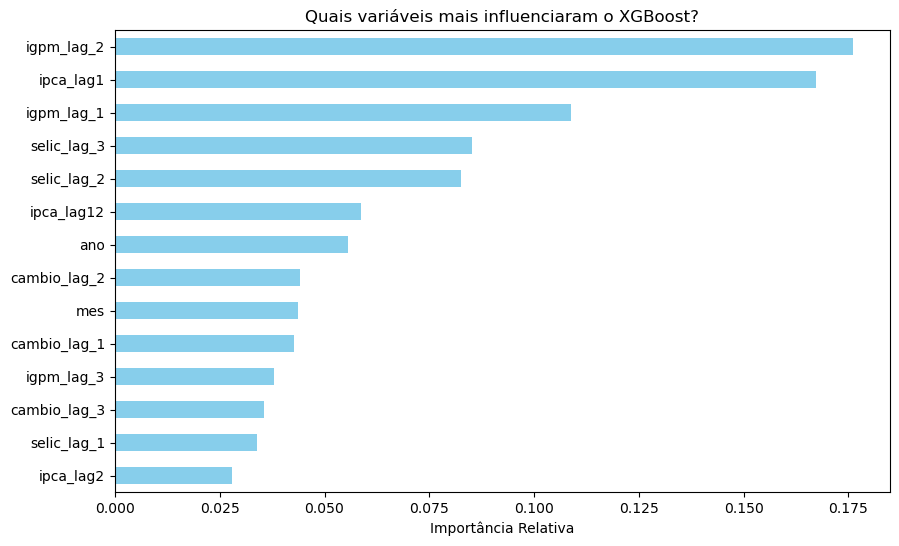

In [27]:
import matplotlib.pyplot as plt

# Criando o ranking de importância
importancia = pd.Series(modelo_xgb.feature_importances_, index=features).sort_values(ascending=True)

# Plotando
plt.figure(figsize=(10, 6))
importancia.plot(kind='barh', color='skyblue')
plt.title('Quais variáveis mais influenciaram o XGBoost?')
plt.xlabel('Importância Relativa')
plt.show()

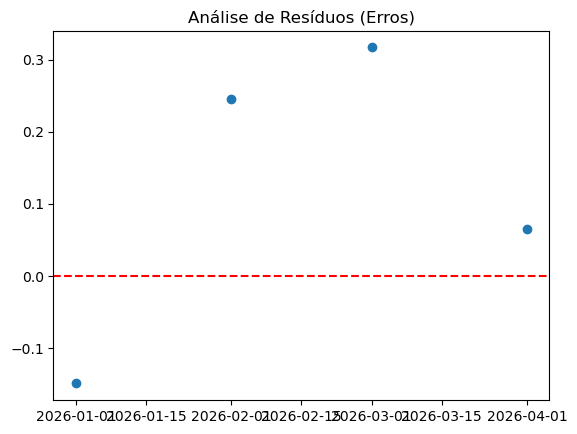

In [28]:
# Gráfico simples de resíduos
plt.scatter(df_comparativo['Data'], df_comparativo['Diferenca'])
plt.axhline(0, color='red', linestyle='--')
plt.title('Análise de Resíduos (Erros)')
plt.show()

Previsão de Maio - Real Forecasting

In [30]:
import pandas as pd

# 1. Pegamos a última linha do seu DataFrame (que é Abril/2026)
ultima_linha = df_limpo.iloc[-1].copy()

# 2. Criamos o "Vetor de Maio" deslocando os valores
# O que era o valor atual em Abril, vira o 'lag_1' em Maio
maio_2026 = {
    'mes': 5,
    'ano': 2026,
    'ipca_lag1': ultima_linha['ipca'],
    'ipca_lag2': ultima_linha['ipca_lag1'],
    'ipca_lag12': df_limpo.iloc[-12]['ipca'], # IPCA de Maio/2025 (sazonalidade)
    
    'selic_lag_1': ultima_linha['selic'],
    'selic_lag_2': ultima_linha['selic_lag_1'],
    'selic_lag_3': ultima_linha['selic_lag_2'],
    
    'cambio_lag_1': ultima_linha['cambio'],
    'cambio_lag_2': ultima_linha['cambio_lag_1'],
    'cambio_lag_3': ultima_linha['cambio_lag_2'],
    
    'igpm_lag_1': ultima_linha['igpm'],
    'igpm_lag_2': ultima_linha['igpm_lag_1'],
    'igpm_lag_3': ultima_linha['igpm_lag_2']
}

# 3. Transformamos em DataFrame e garantimos a ordem das colunas
df_maio = pd.DataFrame([maio_2026])[features]

# 4. A HORA DA VERDADE: O XGBoost faz a previsão
previsao_maio = modelo_xgb.predict(df_maio)[0]

print(f"--- Previsão do IPCA para Maio de 2026 ---")
print(f"Valor Estimado: {previsao_maio:.4f}%")

--- Previsão do IPCA para Maio de 2026 ---
Valor Estimado: 0.4238%
